# Input data overview

What the stress engine starts from: the portfolios in one input set, how many loans they hold, the interest rates on them, and how a loan's stage is set, including the triggers for a significant increase in credit risk (SICR).

The notebook reads files only: the input set `inputs/<hash>/` and the targets transcribed from the requirements into `docs/spec/`. It uses pandas, numpy, PyYAML and matplotlib, imports nothing from the engine or from `nbtools.py`, starts no run and writes nothing.

| Section | Question |
|---|---|
| 1 | Which input set is this, what do its files hold, and is it intact? |
| 2 | Which portfolios are there? |
| 3 | How many loans, and what are they like? |
| 4 | What interest rates do they carry? |
| 5 | Which SICR triggers set the stage? |
| 6 | Opening provisions, parameters and scenarios at a glance |
| 7 | Summary of the checks, and the answers in short |

Along the way the notebook checks the input set against its own manifest and against the targets in `docs/spec/targets.yaml` and `calibration_targets.yaml`. No expected value is typed in by hand, and the tolerances come from the targets file.

## Settings

`INPUTS` names the input set, relative to the repository root. The current input set is `d62d0386f2c5256e`; the v1 set `514ed0e86e3dc760` still opens, without the trigger columns' observation date. `ROWS` and `YAML_LINES` set how much of each file section 1 shows. `SEGMENT` picks the reference segment for the SICR illustration in section 5: P01–P05, P06_GG or P06_CI.

In [1]:
INPUTS = "inputs/d62d0386f2c5256e"  # the input set, relative to the repository root
ROWS = 20  # rows shown from each table in section 1
YAML_LINES = 40  # lines shown from each YAML file in section 1
SEGMENT = "P03"  # the reference segment of the SICR illustration in section 5

In [2]:
import hashlib
import json
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
INPUT_DIR = ROOT / INPUTS
SPEC_DIR = ROOT / "docs" / "spec"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", 100)

# The colours of the other notebooks: stages run from light to dark blue, scenarios keep theirs.
STAGE_COLOURS = {1: "#86b6ef", 2: "#2a78d6", 3: "#104281"}
SCENARIO_COLOURS = {"baseline": "#2a78d6", "adverse": "#eb6834"}
INK, INK_SECONDARY, MUTED, GRID, AXIS, SURFACE = (
    "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb")
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "semibold",
    "text.color": INK, "axes.labelcolor": INK_SECONDARY,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "legend.frameon": False, "legend.fontsize": 8.5,
})


def read_yaml(path: Path) -> dict:
    return yaml.safe_load(path.read_text(encoding="utf-8"))


def listed(values: pd.Series) -> str:
    """The distinct values of a column, sorted and joined, for a table cell."""
    return ", ".join(sorted(str(v) for v in values.dropna().unique())).replace("_", " ")


CHECKS = []  # every check, for the summary in section 7


def compare(what: str, actual, expected, limit: float) -> None:
    """Record and print the largest |actual - expected|; a missing value counts as a failure."""
    a = np.asarray(actual, dtype=float)
    b = np.asarray(expected, dtype=float)
    gap = float(np.max(np.abs(a - b))) if len(a) and len(a) == len(b) else np.nan
    CHECKS.append({"check": what, "values": len(a), "gap": gap, "limit": limit})
    print(f"{what}: {len(a):,} values; largest gap {gap:.1e} (limit {limit:.0e})")


def count_breaks(what: str, broken) -> None:
    """Record and print how many values break a rule; none may."""
    broken = np.asarray(broken, dtype=bool)
    CHECKS.append({"check": what, "values": len(broken), "gap": float(broken.sum()), "limit": 0.0})
    print(f"{what}: {len(broken):,} values; {int(broken.sum()):,} break the rule")

## 1 · The input set

An input set is a folder named after the first 16 characters of its content hash. The one-off step `foundation.synth` (O2–O4) wrote it once, from a fixed seed, and nothing has edited it since. It holds seven datasets: five Parquet tables and two YAML files. `manifest.json` records each file's row count and SHA-256 hash, so the engine's load step R2 can reject a file that has changed. `approval.json` records whether the project owner has approved the set.

In [3]:
manifest = json.loads((INPUT_DIR / "manifest.json").read_text(encoding="utf-8"))
approval = json.loads((INPUT_DIR / "approval.json").read_text(encoding="utf-8"))
generator = manifest["generator"]
display(pd.Series({
    "input set": INPUT_DIR.name,
    "content hash": manifest["input_set_hash"],
    "data status": manifest["status"],
    "written by": f"{generator['name']} {generator['version']}, seed {generator['seed']}",
    "requirements version": manifest["spec_version"],
    "parameter set": f"{manifest['parameter_set_id']} ({manifest['parameter_set_status']})",
    "owner approval": approval["status"],
}, name="").to_frame())

files = []
for name, entry in manifest["files"].items():
    path = INPUT_DIR / name
    files.append({
        "file": name,
        "rows": len(pd.read_parquet(path)) if path.suffix == ".parquet" else np.nan,
        "rows in manifest": np.nan if entry["rows"] is None else entry["rows"],
        "SHA-256 as in manifest": hashlib.sha256(path.read_bytes()).hexdigest() == entry["sha256"],
    })
files = pd.DataFrame(files).set_index("file")
tables = files.dropna(subset=["rows in manifest"])

count_breaks("Folder name is the start of the content hash",
             [not manifest["input_set_hash"].startswith(INPUT_DIR.name)])
count_breaks("Each file's SHA-256 against the manifest", ~files["SHA-256 as in manifest"])
compare("Rows of each table against the manifest", tables["rows"], tables["rows in manifest"], 0)
files.style.format({"rows": "{:,.0f}", "rows in manifest": "{:,.0f}"}, na_rep="")

,
input set,d62d0386f2c5256e
content hash,d62d0386f2c5256eb50fbc787678fdc420fc5bda42ab5f8100a147d097dc91ee
data status,SYNTHETIC
written by,"foundation.synth 0.1.0, seed 20261231"
requirements version,1.3
parameter set,SYN-PS-0.1-proposed (PROPOSED)
owner approval,PENDING_OWNER_APPROVAL


Folder name is the start of the content hash: 1 values; 0 break the rule
Each file's SHA-256 against the manifest: 7 values; 0 break the rule
Rows of each table against the manifest: 5 values; largest gap 0.0e+00 (limit 0e+00)


,rows,rows in manifest,SHA-256 as in manifest
file,,,
commitments.parquet,931,931,True
facilities.parquet,"10,000","10,000",True
obligors.parquet,"8,320","8,320",True
opening_provisions.parquet,"10,000","10,000",True
parameter_set.yaml,,,True
scenarios.yaml,,,True
ttc_pd_matrix.parquet,847,847,True


The tables are read once here and joined into `book`: one row per facility, with its obligor's attributes, its undrawn commitment (zero where there is none) and its frozen opening provision. Each facility also gets the one-year TTC PD of its current grade, which is the D column of its segment's TTC matrix.

In [4]:
facilities = pd.read_parquet(INPUT_DIR / "facilities.parquet")
obligors = pd.read_parquet(INPUT_DIR / "obligors.parquet")
commitments = pd.read_parquet(INPUT_DIR / "commitments.parquet")
provisions = pd.read_parquet(INPUT_DIR / "opening_provisions.parquet")
ttc_table = pd.read_parquet(INPUT_DIR / "ttc_pd_matrix.parquet")
ps = read_yaml(INPUT_DIR / "parameter_set.yaml")
scenario_doc = read_yaml(INPUT_DIR / "scenarios.yaml")
targets = read_yaml(SPEC_DIR / "targets.yaml")
calibration = read_yaml(SPEC_DIR / "calibration_targets.yaml")["segments"]

NAMES = {p: v["name"] for p, v in targets["portfolios"].items()}  # the section 5.1 names
UNIT = {"EUR_million": 1e6}[targets["unit"]]  # the targets file states amounts in EUR million
TOL = targets["tolerances"]


def aggregate_limit(expected) -> float:
    """The targets' tolerance for aggregate amounts: the larger of abs and rel x the amount."""
    return max(TOL["aggregate"]["abs"], TOL["aggregate"]["rel"] * float(np.max(np.abs(expected))))


GRADES = list(ps["master_scale"]["grades"])  # performing grades, best first
DEFAULT = ps["master_scale"]["default_grade"]
LABELS = [*GRADES, DEFAULT]
N = len(GRADES)
RANK = {g: i + 1 for i, g in enumerate(LABELS)}  # 1..N for performing grades, N + 1 for D
STAGES = (1, 2, 3)

book = (
    facilities
    .merge(obligors[["obligor_id", "group_id", "country", "counterparty_sector", "nace_code",
                     "sme_flag", "regulatory_default"]],
           on="obligor_id", how="left", validate="many_to_one")
    .merge(commitments[["facility_id", "nominal_undrawn", "accounting_ccf"]],
           on="facility_id", how="left", validate="one_to_one")
    .merge(provisions[["facility_id", "allowance_on", "provision_off", "overlay_amount"]],
           on="facility_id", how="left", validate="one_to_one")
)
book["nominal_undrawn"] = book["nominal_undrawn"].fillna(0.0)
one_year = ttc_table[ttc_table["to_grade"] == DEFAULT].set_index(["segment", "from_grade"])
book["ttc_pd"] = one_year["probability"].reindex(
    pd.MultiIndex.from_arrays([book["segment"], book["current_grade"]])).to_numpy()

print(f"{len(facilities):,} facilities, {len(obligors):,} obligors in "
      f"{obligors['group_id'].nunique():,} connected groups, {len(commitments):,} undrawn "
      f"commitments, {len(provisions):,} opening provisions; "
      f"snapshot date {ps['horizon']['snapshot_date']}")

10,000 facilities, 8,320 obligors in 8,282 connected groups, 931 undrawn commitments, 10,000 opening provisions; snapshot date 2026-12-31


### The files as stored

The first `ROWS` rows of each Parquet table, exactly as stored: every column, unchanged values. Amounts are in EUR, and rates and probabilities are decimal fractions (0.03 is 3%). Dates are ISO strings. A column whose name ends in `__status` records the status of the column of the same name, for example `supplied` or `not_applicable`. Where a table has no such column, the engine infers the status from the value.

In [5]:
TABLES = {
    "facilities.parquet": (facilities, "one row per facility (loan or debt security)"),
    "obligors.parquet": (obligors, "one row per borrower"),
    "commitments.parquet": (commitments, "one row per undrawn commitment, linked to a facility"),
    "opening_provisions.parquet": (
        provisions, f"one row per facility: its provision, frozen at {ps['horizon']['snapshot_date']}"),
    "ttc_pd_matrix.parquet": (ttc_table, "one row per segment, from grade and to grade"),
}
for name, (table, grain) in TABLES.items():
    display(Markdown(f"**{name}**: {grain}; {len(table):,} rows × {table.shape[1]} columns, "
                     f"the first {min(ROWS, len(table))} shown"))
    display(table.head(ROWS))

**facilities.parquet**: one row per facility (loan or debt security); 10,000 rows × 39 columns, the first 20 shown

,facility_id,obligor_id,entity_id,portfolio,segment,product,ifrs_stage,poci,accounting_category,currency,principal,accrued_interest,accrued_in_gca,gca,contractual_limit,interest_rate,rate_type,residual_maturity,repayment_profile,regulatory_approach,regulatory_class,current_grade,origination_grade,ttc_lgd,dpd,watchlist,forborne,credit_status_date,origination_date,stage_entry_date,default_date,default_date__status,collateral_type,collateral_type__status,ltv,ltv__status,dscr,dscr__status,snapshot_date
0,F00001,O00001,NLBANK,P01,P01,mortgage,1,False,AC,EUR,340959.775314,1798.960833,True,342758.736147,340959.775314,0.026097,floating,25.000000,bullet,IRB,retail_secured_by_immovable_property,G4,G4,0.134375,0,False,False,2026-12-31,2019-08-12,2019-08-12,NaN,not_applicable,residential_property,supplied,0.758761,supplied,NaN,not_applicable,2026-12-31
1,F00002,O00002,NLBANK,P01,P01,mortgage,1,False,AC,EUR,403193.537056,1176.078221,True,404369.615277,403193.537056,0.033311,fixed,22.500000,annuity,STA,secured_by_mortgages_on_residential_property,G4,G4,0.165533,0,False,False,2026-12-31,2021-04-21,2021-04-21,NaN,not_applicable,residential_property,supplied,0.877762,supplied,NaN,not_applicable,2026-12-31
2,F00003,O00003,NLBANK,P01,P01,mortgage,1,False,AC,EUR,300971.094443,1302.926288,True,302274.020731,300971.094443,0.033222,fixed,17.250000,annuity,IRB,retail_secured_by_immovable_property,G4,G5,0.119487,0,False,False,2026-12-31,2022-04-19,2022-04-19,NaN,not_applicable,residential_property,supplied,0.555254,supplied,NaN,not_applicable,2026-12-31
3,F00004,O00004,NLBANK,P01,P01,mortgage,1,False,AC,EUR,177307.753264,311.681458,True,177619.434722,177307.753264,0.023099,fixed,18.166667,bullet,IRB,retail_secured_by_immovable_property,G4,G3,0.172864,0,False,False,2026-12-31,2025-11-01,2025-11-01,NaN,not_applicable,residential_property,supplied,0.700196,supplied,NaN,not_applicable,2026-12-31
4,F00005,O00005,NLBANK,P01,P01,mortgage,1,False,AC,EUR,478263.117706,2729.232628,True,480992.350334,478263.117706,0.030354,fixed,24.166667,annuity,STA,secured_by_mortgages_on_residential_property,G4,G4,0.188620,0,False,False,2026-12-31,2017-06-14,2017-06-14,NaN,not_applicable,residential_property,supplied,0.691100,supplied,NaN,not_applicable,2026-12-31
5,F00006,O00006,NLBANK,P01,P01,mortgage,1,False,AC,EUR,146076.829472,425.046247,True,146501.875719,146076.829472,0.031578,fixed,17.083333,annuity,STA,secured_by_mortgages_on_residential_property,G4,G3,0.123892,0,False,False,2026-12-31,2023-06-24,2023-06-24,NaN,not_applicable,residential_property,supplied,0.895019,supplied,NaN,not_applicable,2026-12-31
6,F00007,O00007,NLBANK,P01,P01,mortgage,1,False,AC,EUR,332280.719359,1678.066850,True,333958.786209,332280.719359,0.031579,floating,14.416667,annuity,IRB,retail_secured_by_immovable_property,G4,G5,0.133570,23,False,False,2026-12-31,2019-01-17,2019-01-17,NaN,not_applicable,residential_property,supplied,0.646878,supplied,NaN,not_applicable,2026-12-31
7,F00008,O00008,NLBANK,P01,P01,mortgage,1,False,AC,EUR,243038.026632,737.565908,True,243775.592540,243038.026632,0.027568,fixed,12.583333,annuity,STA,secured_by_mortgages_on_residential_property,G4,G3,0.129182,0,False,False,2026-12-31,2024-03-18,2024-03-18,NaN,not_applicable,residential_property,supplied,0.782980,supplied,NaN,not_applicable,2026-12-31
8,F00009,O00009,NLBANK,P01,P01,mortgage,1,False,AC,EUR,436740.422640,1203.458437,True,437943.881076,436740.422640,0.034253,fixed,19.416667,annuity,STA,secured_by_mortgages_on_residential_property,G4,G4,0.123047,0,False,False,2026-12-31,2017-09-08,2017-09-08,NaN,not_applicable,residential_property,supplied,0.690977,supplied,NaN,not_applicable,2026-12-31
9,F00010,O00010,NLBANK,P01,P01,mortgage,1,False,AC,EUR,124508.212123,672.205157,True,125180.417281,124508.212123,0.033907,fixed,25.583333,annuity,STA,secured_by_mortgages_on_residential_property,G4,G5,0.104599,0,False,False,2026-12-31,2020-03-10,2020-03-10,NaN,not_applicable,residential_property,supplied,0.685331,supplied,NaN,not

**obligors.parquet**: one row per borrower; 8,320 rows × 14 columns, the first 20 shown

,obligor_id,group_id,entity_id,country,counterparty_sector,nace_code,nace_code__status,nace_version,nace_version__status,principal_activity,principal_activity__status,sme_flag,regulatory_default,snapshot_date
0,O00001,GRP-O00001,NLBANK,NL,households,NaN,not_applicable,NaN,not_applicable,NaN,not_applicable,False,False,2026-12-31
1,O00002,GRP-O00002,NLBANK,NL,households,NaN,not_applicable,NaN,not_applicable,NaN,not_applicable,False,False,2026-12-31
2,O00003,GRP-O00003,NLBANK,NL,households,NaN,not_applicable,NaN,not_applicable,NaN,not_applicable,False,False,2026-12-31
3,O00004,GRP-O00004,NLBANK,DE,households,NaN,not_applicable,NaN,not_applicable,NaN,not_applicable,False,False,2026-12-31
4,O00005,GRP-O00005,NLBANK,PL,households,NaN,not_applicable,NaN,not_applicable,NaN,not_applicable,False,False,2026-12-31
5,O00006,GRP-O00006,NLBANK,PL,households,NaN,not_applicable,NaN,not_applicable,NaN,not_applicable,False,False,2026-12-31
6,O00007,GRP-O00007,NLBANK,IT,households,NaN,not_applicable,NaN,not_applicable,NaN,not_applicable,False,False,2026-12-31
7,O00008,GRP-O00008,NLBANK,NL,households,NaN,not_applicable,NaN,not_applicable,NaN,not_applicable,False,False,2026-12-31
8,O00009,GRP-O00009,NLBANK,DE,households,NaN,not_applicable,NaN,not_applicable,NaN,not_applicable,False,False,2026-12-31
9,O00010,GRP-O00010,NLBANK,DE,households,NaN,not_applicable,NaN,not_applicable,NaN,not_applicable,False,False,2026-12-31


**commitments.parquet**: one row per undrawn commitment, linked to a facility; 931 rows × 9 columns, the first 20 shown

,commitment_id,facility_id,nominal_undrawn,accounting_ccf,currency,ccf_source,asset_category,provision_classification,snapshot_date
0,C00001,F07007,1.318837e+06,0.5,EUR,SYN-PAR-07 section 5.1 test CCF,not_applicable,off_balance_loan_commitment,2026-12-31
1,C00002,F07010,7.225774e+05,0.5,EUR,SYN-PAR-07 section 5.1 test CCF,not_applicable,off_balance_loan_commitment,2026-12-31
2,C00003,F07011,1.875611e+06,0.5,EUR,SYN-PAR-07 section 5.1 test CCF,not_applicable,off_balance_loan_commitment,2026-12-31
3,C00004,F07014,1.117858e+06,0.5,EUR,SYN-PAR-07 section 5.1 test CCF,not_applicable,off_balance_loan_commitment,2026-12-31
4,C00005,F07015,8.743213e+05,0.5,EUR,SYN-PAR-07 section 5.1 test CCF,not_applicable,off_balance_loan_commitment,2026-12-31
5,C00006,F07019,2.270799e+06,0.5,EUR,SYN-PAR-07 section 5.1 test CCF,not_applicable,off_balance_loan_commitment,2026-12-31
6,C00007,F07020,1.077877e+06,0.5,EUR,SYN-PAR-07 section 5.1 test CCF,not_applicable,off_balance_loan_commitment,2026-12-31
7,C00008,F07023,2.259222e+06,0.5,EUR,SYN-PAR-07 section 5.1 test CCF,not_applicable,off_balance_loan_commitment,2026-12-31
8,C00009,F07024,8.207632e+05,0.5,EUR,SYN-PAR-07 section 5.1 test CCF,not_applicable,off_balance_loan_commitment,2026-12-31
9,C00010,F07030,1.037878e+06,0.5,EUR,SYN-PAR-07 section 5.1 test CCF,not_applicable,off_balance_loan_commitment,2026-12-31


**opening_provisions.parquet**: one row per facility: its provision, frozen at 2026-12-31; 10,000 rows × 14 columns, the first 20 shown

,facility_id,currency,allowance_on,provision_off,overlay_amount,overlay_risk,overlay_risk__status,overlay_owner,overlay_owner__status,overlay_reason,overlay_reason__status,method,frozen,snapshot_date
0,F00001,EUR,134.660283,0.0,0.0,None,not_applicable,None,not_applicable,None,not_applicable,O4 TTC formula v1 (SYN-PAR-09),True,2026-12-31
1,F00002,EUR,194.336013,0.0,0.0,None,not_applicable,None,not_applicable,None,not_applicable,O4 TTC formula v1 (SYN-PAR-09),True,2026-12-31
2,F00003,EUR,104.869740,0.0,0.0,None,not_applicable,None,not_applicable,None,not_applicable,O4 TTC formula v1 (SYN-PAR-09),True,2026-12-31
3,F00004,EUR,90.032543,0.0,0.0,None,not_applicable,None,not_applicable,None,not_applicable,O4 TTC formula v1 (SYN-PAR-09),True,2026-12-31
4,F00005,EUR,264.155934,0.0,0.0,None,not_applicable,None,not_applicable,None,not_applicable,O4 TTC formula v1 (SYN-PAR-09),True,2026-12-31
5,F00006,EUR,52.784250,0.0,0.0,None,not_applicable,None,not_applicable,None,not_applicable,O4 TTC formula v1 (SYN-PAR-09),True,2026-12-31
6,F00007,EUR,129.724158,0.0,0.0,None,not_applicable,None,not_applicable,None,not_applicable,O4 TTC formula v1 (SYN-PAR-09),True,2026-12-31
7,F00008,EUR,91.939442,0.0,0.0,None,not_applicable,None,not_applicable,None,not_applicable,O4 TTC formula v1 (SYN-PAR-09),True,2026-12-31
8,F00009,EUR,156.309378,0.0,0.0,None,not_applicable,None,not_applicable,None,not_applicable,O4 TTC formula v1 (SYN-PAR-09),True,2026-12-31
9,F00010,EUR,37.993154,0.0,0.0,None,not_applicable,None,not_applicable,None,not_applicable,O4 TTC formula v1 (SYN-PAR-09),True,2026-12-31


**ttc_pd_matrix.parquet**: one row per segment, from grade and to grade; 847 rows × 7 columns, the first 20 shown

,segment,from_grade,to_grade,probability,from_rank,to_rank,master_scale_pd
0,P01,G1,G1,0.944811,1,1,0.0002
1,P01,G1,G2,0.038493,1,2,0.0002
2,P01,G1,G3,0.011548,1,3,0.0002
3,P01,G1,G4,0.003464,1,4,0.0002
4,P01,G1,G5,0.001039,1,5,0.0002
5,P01,G1,G6,0.000312,1,6,0.0002
6,P01,G1,G7,0.000094,1,7,0.0002
7,P01,G1,G8,0.000028,1,8,0.0002
8,P01,G1,G9,0.000008,1,9,0.0002
9,P01,G1,G10,0.000003,1,10,0.0002


The two YAML files are nested documents rather than tables, so their first `YAML_LINES` lines are shown as raw text. After the raw text come the scenario values, the `values` list of `scenarios.yaml`, laid out as a table: one row per scenario, variable, country and year.

In [6]:
for name in ("parameter_set.yaml", "scenarios.yaml"):
    lines = (INPUT_DIR / name).read_text(encoding="utf-8").splitlines()
    display(Markdown(f"**{name}**: {len(lines):,} lines, the first "
                     f"{min(YAML_LINES, len(lines))} shown"))
    print("\n".join(lines[:YAML_LINES]))

scenario_values = pd.DataFrame(scenario_doc["values"])
display(Markdown(f"**scenarios.yaml**, `values` as a table: {len(scenario_values):,} rows × "
                 f"{scenario_values.shape[1]} columns, the first {min(ROWS, len(scenario_values))} "
                 "shown"))
display(scenario_values.head(ROWS))

**parameter_set.yaml**: 242 lines, the first 40 shown

parameter_set_id: SYN-PS-0.1-proposed
version: '0.1'
status: PROPOSED
spec_version: '1.3'
horizon:
  snapshot_date: '2026-12-31'
  snapshot_year: 2026
  projection_years:
  - 2027
  - 2028
  - 2029
  last_bucket_year: 2060
master_scale:
  grades:
  - G1
  - G2
  - G3
  - G4
  - G5
  - G6
  - G7
  - G8
  - G9
  - G10
  default_grade: D
  ttc_pd:
  - 0.0002
  - 0.0005
  - 0.0012
  - 0.003
  - 0.007
  - 0.016
  - 0.03
  - 0.048
  - 0.09
  - 0.18
segments:
  P01:
    portfolio: P01
    z_drivers:


**scenarios.yaml**: 2,164 lines, the first 40 shown

scenario_set_id: SYN-SCN-1.3
source: requirements v1.3 section 6.2 (illustrative common paths)
release: '2026-10-17'
revision: 1
status: SYNTHETIC
scenarios:
- id: baseline
  label: Baseline
  status: SYNTHETIC
  source_type: synthetic
- id: adverse
  label: Adverse
  status: SYNTHETIC
  source_type: synthetic
variables:
- id: gdp_growth
  label: Real GDP annual growth
  unit: percent
  value_type: growth
- id: unemployment
  label: Unemployment level
  unit: percent
  value_type: level
- id: residential_price_change
  label: Residential property annual price change
  unit: percent
  value_type: growth
- id: cre_price_change
  label: CRE annual price change
  unit: percent
  value_type: growth
- id: reference_rate
  label: Reference interest rate level
  unit: percent
  value_type: level
starting_values:
- variable: unemployment
  country: NL
  year: 2026
  value: 6.0


**scenarios.yaml**, `values` as a table: 180 rows × 11 columns, the first 20 shown

,scenario,variable,country,year,value,unit,value_type,source,release,completeness,status
0,baseline,gdp_growth,NL,2027,1.5,percent,growth,requirements v1.3 section 6.2 (illustrative common paths),2026-10-17,complete,SYNTHETIC
1,baseline,gdp_growth,NL,2028,1.7,percent,growth,requirements v1.3 section 6.2 (illustrative common paths),2026-10-17,complete,SYNTHETIC
2,baseline,gdp_growth,NL,2029,1.8,percent,growth,requirements v1.3 section 6.2 (illustrative common paths),2026-10-17,complete,SYNTHETIC
3,baseline,gdp_growth,DE,2027,1.5,percent,growth,requirements v1.3 section 6.2 (illustrative common paths),2026-10-17,complete,SYNTHETIC
4,baseline,gdp_growth,DE,2028,1.7,percent,growth,requirements v1.3 section 6.2 (illustrative common paths),2026-10-17,complete,SYNTHETIC
5,baseline,gdp_growth,DE,2029,1.8,percent,growth,requirements v1.3 section 6.2 (illustrative common paths),2026-10-17,complete,SYNTHETIC
6,baseline,gdp_growth,FR,2027,1.5,percent,growth,requirements v1.3 section 6.2 (illustrative common paths),2026-10-17,complete,SYNTHETIC
7,baseline,gdp_growth,FR,2028,1.7,percent,growth,requirements v1.3 section 6.2 (illustrative common paths),2026-10-17,complete,SYNTHETIC
8,baseline,gdp_growth,FR,2029,1.8,percent,growth,requirements v1.3 section 6.2 (illustrative common paths),2026-10-17,complete,SYNTHETIC
9,baseline,gdp_growth,ES,2027,1.5,percent,growth,requirements v1.3 section 6.2 (illustrative common paths),2026-10-17,complete,SYNTHETIC


## 2 · Portfolios

The book holds six portfolios, P01–P06, with the names used in §5.1 of the requirements. Each facility also belongs to a reference segment, which selects its TTC rating matrix and its parameters. Segments and portfolios match one to one, except P06, which splits into general governments (P06_GG) and credit institutions (P06_CI). Every exposure is in EUR and held at amortised cost (AC).

GCA is the gross carrying amount: drawn principal plus accrued interest, with the interest counted once. The undrawn column is the nominal amount of the off-balance commitments.

In [7]:
by_p = book.groupby("portfolio")
gca = by_p["gca"].sum()
irb = book[book["regulatory_approach"] == "IRB"].groupby("portfolio")["gca"].sum()
portfolios = pd.DataFrame({
    "name": pd.Series(NAMES),
    "segments": by_p["segment"].agg(listed),
    "products": by_p["product"].agg(listed),
    "counterparties": by_p["counterparty_sector"].agg(listed),
    "facilities": by_p.size(),
    "obligors": by_p["obligor_id"].nunique(),
    "GCA €m": gca / 1e6,
    "share of GCA": gca / gca.sum(),
    "undrawn €m": by_p["nominal_undrawn"].sum() / 1e6,
    "IRB share": irb.reindex(gca.index, fill_value=0.0) / gca,
    "average GCA €k": gca / by_p.size() / 1e3,
})
portfolios.loc["Total"] = pd.Series({
    "facilities": len(book), "obligors": book["obligor_id"].nunique(),
    "GCA €m": gca.sum() / 1e6, "share of GCA": 1.0,
    "undrawn €m": book["nominal_undrawn"].sum() / 1e6, "IRB share": irb.sum() / gca.sum(),
    "average GCA €k": gca.sum() / len(book) / 1e3,
})
portfolios.style.format({
    "facilities": "{:,.0f}", "obligors": "{:,.0f}", "GCA €m": "{:,.1f}", "share of GCA": "{:.1%}",
    "undrawn €m": "{:,.1f}", "IRB share": "{:.0%}", "average GCA €k": "{:,.0f}"}, na_rep="")

,name,segments,products,counterparties,facilities,obligors,GCA €m,share of GCA,undrawn €m,IRB share,average GCA €k
P01,Residential mortgages,P01,mortgage,households,"4,000","3,640","1,200.0",10.9%,0.0,60%,300
P02,Consumer credit,P02,consumer loan,households,"3,000","3,000",60.0,0.5%,0.0,40%,20
P03,SME lending,P03,"revolver, term loan",non financial corporations,"1,500",881,"1,500.0",13.6%,600.0,50%,"1,000"
P04,Commercial real estate,P04,term loan,non financial corporations,500,309,"2,000.0",18.2%,0.0,70%,"4,000"
P05,Corporate lending,P05,"revolver, term loan",non financial corporations,800,447,"4,000.0",36.4%,"1,400.0",70%,"5,000"
P06,Sovereigns and credit institutions,"P06 CI, P06 GG",debt security,"credit institutions, general governments",200,43,"2,240.0",20.4%,0.0,0%,"11,200"
Total,,,,,"10,000","8,320","11,000.0",100.0%,"2,000.0",52%,"1,100"


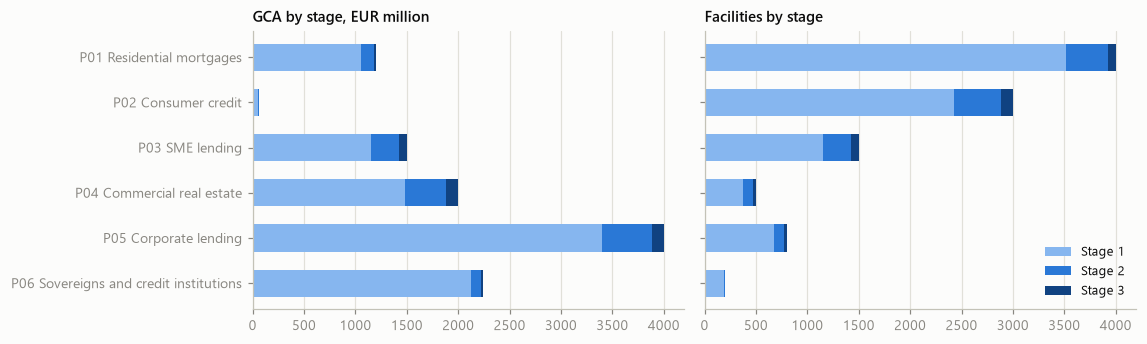

In [8]:
order = list(NAMES)
ylabels = [f"{p} {NAMES[p]}" for p in order]
stage_gca = book.pivot_table(index="portfolio", columns="ifrs_stage", values="gca",
                             aggfunc="sum").reindex(order) / 1e6
stage_count = pd.crosstab(book["portfolio"], book["ifrs_stage"]).reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.2), sharey=True)
for ax, table, title in ((axes[0], stage_gca, "GCA by stage, EUR million"),
                         (axes[1], stage_count, "Facilities by stage")):
    left = np.zeros(len(order))
    for s in STAGES:
        ax.barh(ylabels, table[s], left=left, height=0.6, color=STAGE_COLOURS[s],
                label=f"Stage {s}")
        left += table[s].to_numpy()
    ax.set_title(title, loc="left")
    ax.grid(True, axis="x")
    ax.grid(False, axis="y")
axes[0].invert_yaxis()
axes[1].legend(loc="lower right")
fig.tight_layout()
plt.show()

The size of each portfolio against the targets of §5.1 and §5.3: facilities, GCA and undrawn amounts, the IRB share of GCA, the split between IRB and STA, and the P06 split between governments and banks.

In [9]:
count_breaks(f"Every facility in {targets['currency']} at {targets['accounting_category']}",
             (book["currency"] != targets["currency"])
             | (book["accounting_category"] != targets["accounting_category"]))
tp = pd.DataFrame(targets["portfolios"]).T
compare("Facilities per portfolio against §5.1", portfolios.loc[tp.index, "facilities"],
        tp["facilities"], 0)
for column, key in (("gca", "gca"), ("nominal_undrawn", "undrawn")):
    expected = tp[key].astype(float) * UNIT
    compare(f"{key.upper() if key == 'gca' else key.capitalize()} per portfolio against §5.1, EUR",
            by_p[column].sum()[tp.index], expected, aggregate_limit(expected))
irb_target = pd.Series(targets["irb_share"])
compare("IRB share of GCA per portfolio against §5.3",
        portfolios.loc[irb_target.index, "IRB share"], irb_target, TOL["rate"]["abs"])
approach = book.groupby("regulatory_approach")["gca"].sum()
expected = pd.Series({a: targets["approach_totals"][a] * UNIT for a in approach.index})
compare("GCA per regulatory approach against §5.3, EUR", approach, expected,
        aggregate_limit(expected))
p06 = book[book["portfolio"] == "P06"].groupby("counterparty_sector")["gca"].sum()
p06_target = pd.Series(targets["p06_counterparties"])
compare("P06 share of GCA per counterparty sector against §5.3",
        (p06 / p06.sum()).reindex(p06_target.index), p06_target, TOL["rate"]["abs"])

Every facility in EUR at AC: 10,000 values; 0 break the rule
Facilities per portfolio against §5.1: 6 values; largest gap 0.0e+00 (limit 0e+00)
GCA per portfolio against §5.1, EUR: 6 values; largest gap 1.4e-06 (limit 4e+01)
Undrawn per portfolio against §5.1, EUR: 6 values; largest gap 0.0e+00 (limit 1e+01)
IRB share of GCA per portfolio against §5.3: 6 values; largest gap 6.1e-16 (limit 1e-10)
GCA per regulatory approach against §5.3, EUR: 2 values; largest gap 9.5e-07 (limit 6e+01)
P06 share of GCA per counterparty sector against §5.3: 2 values; largest gap 3.9e-16 (limit 1e-10)


## 3 · Loans

Each loan is one row of `facilities`, a single facility of a single obligor. The obligor carries the borrower attributes: country, sector, NACE code, connected group and regulatory default. A revolving facility can also have one undrawn commitment.

### Opening stages

§5.2 fixes the number of facilities and the GCA in each portfolio and stage at the snapshot date.

In [10]:
counts = pd.crosstab(book["portfolio"], book["ifrs_stage"], margins=True, margins_name="Total")
amounts = pd.crosstab(book["portfolio"], book["ifrs_stage"], values=book["gca"], aggfunc="sum",
                      margins=True, margins_name="Total") / 1e6
stage_table = pd.concat({"facilities": counts, "GCA €m": amounts}, axis=1)
stage_table.columns.names = [None, "stage"]

expected = pd.DataFrame([
    {"portfolio": p, "ifrs_stage": s, "count": v["count"][s], "gca": v["gca"][s] * UNIT}
    for p, v in targets["stages"].items() if p != "Total" for s in STAGES
]).set_index(["portfolio", "ifrs_stage"])
actual = (book.groupby(["portfolio", "ifrs_stage"])
          .agg(count=("gca", "size"), gca=("gca", "sum")).reindex(expected.index))
compare("Facilities per portfolio and stage against §5.2", actual["count"], expected["count"], 0)
compare("GCA per portfolio and stage against §5.2, EUR", actual["gca"], expected["gca"],
        aggregate_limit(expected["gca"]))
stage_table.style.format(
    {c: "{:,.0f}" if c[0] == "facilities" else "{:,.1f}" for c in stage_table.columns})

Facilities per portfolio and stage against §5.2: 18 values; largest gap 0.0e+00 (limit 0e+00)
GCA per portfolio and stage against §5.2, EUR: 18 values; largest gap 1.2e-06 (limit 3e+01)


### Products, maturities and risk attributes

Products per portfolio, broken down by the contractual repayment profile in `repayment_profile`. The engine does not build cash flows from that column. R5 takes the profile per product from the run variant, and the core run uses a bullet profile for every facility (SYN-PAR-07). R3 only checks that the column holds a valid profile.

In [11]:
pd.crosstab([book["portfolio"], book["product"]], book["repayment_profile"],
            margins=True, margins_name="Total")

repayment_profile        annuity  bullet  linear  Total
portfolio product                                      
P01       mortgage          3614     386       0   4000
P02       consumer_loan     3000       0       0   3000
P03       revolver             0     553       0    553
          term_loan            0     366     581    947
P04       term_loan            0     355     145    500
P05       revolver             0     378       0    378
          term_loan            0     209     213    422
P06       debt_security        0     200       0    200
Total                       6614    2447     939  10000

Each risk attribute against its proposed test range in §5.4. The PD range applies to performing facilities only; here it is checked with the one-year TTC PD of the current grade. LTV is set for P01 and P04, DSCR for P04 only.

In [12]:
ATTRIBUTES = {  # column: (range key in targets.yaml, label, stages it applies to)
    "ttc_pd": ("performing_pd", "one-year TTC PD of the current grade", (1, 2)),
    "ttc_lgd": ("lgd", "TTC LGD", STAGES),
    "residual_maturity": ("residual_maturity_years", "residual maturity, years", STAGES),
    "ltv": ("ltv", "LTV", STAGES),
    "dscr": ("dscr", "DSCR", STAGES),
}
rows, outside = [], {}
for p, profile in targets["risk_profiles"].items():
    for column, (key, label, stages) in ATTRIBUTES.items():
        if key not in profile:
            continue
        values = book.loc[(book["portfolio"] == p) & book["ifrs_stage"].isin(stages), column]
        lo, hi = profile[key]
        broken = (values < lo) | (values > hi)
        outside.setdefault(label, []).append(broken.to_numpy())
        rows.append({"portfolio": p, "attribute": label, "§5.4 from": lo, "§5.4 to": hi,
                     "min": values.min(), "median": values.median(), "max": values.max(),
                     "outside": int(broken.sum())})
for label, broken in outside.items():
    count_breaks(f"{label[0].upper() + label[1:]} within the §5.4 range", np.concatenate(broken))
ranges = pd.DataFrame(rows).set_index(["portfolio", "attribute"])
ranges.style.format("{:.4g}", subset=["§5.4 from", "§5.4 to", "min", "median", "max"])

One-year TTC PD of the current grade within the §5.4 range: 9,669 values; 0 break the rule
TTC LGD within the §5.4 range: 10,000 values; 0 break the rule
Residual maturity, years within the §5.4 range: 10,000 values; 0 break the rule
LTV within the §5.4 range: 4,500 values; 0 break the rule
DSCR within the §5.4 range: 500 values; 0 break the rule


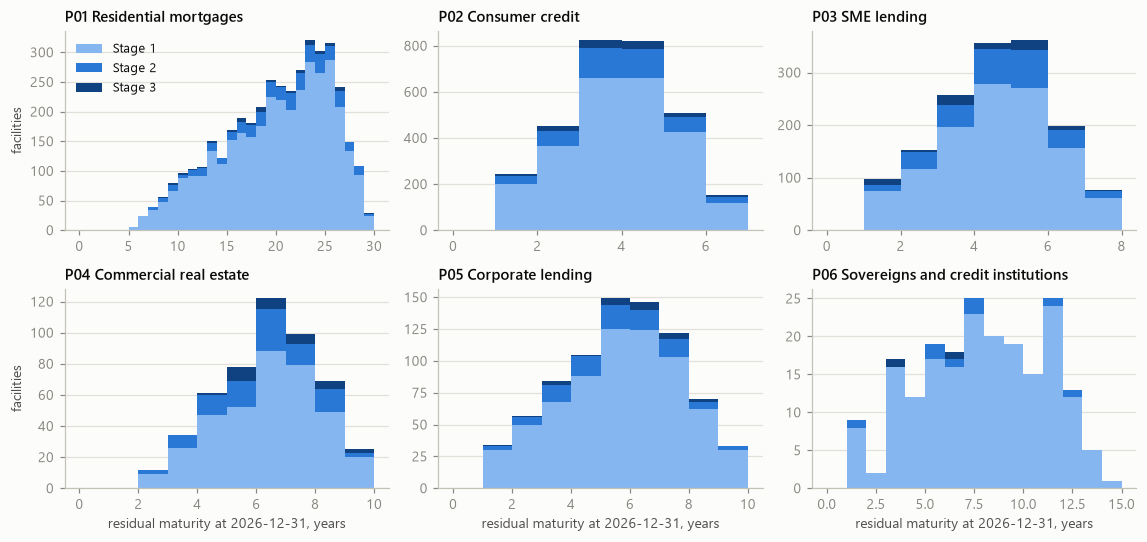

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(10.5, 5))
for ax, p in zip(axes.flat, NAMES):
    part = book[book["portfolio"] == p]
    bins = np.arange(0, np.ceil(part["residual_maturity"].max()) + 1)
    ax.hist([part.loc[part["ifrs_stage"] == s, "residual_maturity"] for s in STAGES], bins=bins,
            stacked=True, color=[STAGE_COLOURS[s] for s in STAGES],
            label=[f"Stage {s}" for s in STAGES])
    ax.set_title(f"{p} {NAMES[p]}", loc="left")
for ax in axes[1]:
    ax.set_xlabel(f"residual maturity at {ps['horizon']['snapshot_date']}, years")
for ax in axes[:, 0]:
    ax.set_ylabel("facilities")
axes[0, 0].legend()
fig.tight_layout()
plt.show()

### Borrowers: countries, sectors and concentration

§5.3 sets one country mix by GCA for every portfolio. Under §5.5, P03 and P05 are spread over NACE sections and P04 is all real estate (section L). SYN-04 sets the share of P04 and P05 GCA held by the ten largest connected groups.

In [14]:
countries = book.pivot_table(index="portfolio", columns="country", values="gca", aggfunc="sum")
countries = countries.div(countries.sum(axis=1), axis=0)[list(targets["countries"])]
compare("Country share of GCA in each portfolio against §5.3", countries.to_numpy().ravel(),
        np.tile(list(targets["countries"].values()), len(countries)), TOL["rate"]["abs"])

sectors = book[book["portfolio"].isin(list(targets["sectors"]))].pivot_table(
    index="nace_code", columns="portfolio", values="gca", aggfunc="sum", fill_value=0.0)
sector_target = pd.DataFrame(targets["sectors"]).fillna(0.0)
sections = sectors.index.union(sector_target.index)
sectors = (sectors / sectors.sum()).reindex(index=sections, columns=sector_target.columns,
                                             fill_value=0.0)
compare("NACE section share of GCA against §5.5", sectors.to_numpy().ravel(),
        sector_target.reindex(sections, fill_value=0.0).to_numpy().ravel(), TOL["rate"]["abs"])

top_groups = targets["concentration_top_groups"]
top = pd.Series({
    p: book[book["portfolio"] == p].groupby("group_id")["gca"].sum()
    .nlargest(top_groups["groups"]).sum() / gca[p]
    for p in NAMES})
top_target = pd.Series(top_groups["share_of_gca"])
compare(f"Share of GCA in the {top_groups['groups']} largest connected groups against SYN-04",
        top[top_target.index], top_target, TOL["rate"]["abs"])

display(countries.style.format("{:.1%}").set_caption("Share of GCA per country"))
display(sectors.style.format("{:.0%}").set_caption("Share of GCA per NACE section"))

Country share of GCA in each portfolio against §5.3: 36 values; largest gap 2.8e-16 (limit 1e-10)
NACE section share of GCA against §5.5: 24 values; largest gap 1.7e-16 (limit 1e-10)
Share of GCA in the 10 largest connected groups against SYN-04: 2 values; largest gap 1.1e-16 (limit 1e-10)


country,NL,DE,FR,ES,IT,PL
portfolio,,,,,,
P01,30.0%,20.0%,15.0%,10.0%,10.0%,15.0%
P02,30.0%,20.0%,15.0%,10.0%,10.0%,15.0%
P03,30.0%,20.0%,15.0%,10.0%,10.0%,15.0%
P04,30.0%,20.0%,15.0%,10.0%,10.0%,15.0%
P05,30.0%,20.0%,15.0%,10.0%,10.0%,15.0%
P06,30.0%,20.0%,15.0%,10.0%,10.0%,15.0%


,P03,P04,P05
A,10%,0%,5%
C,25%,0%,30%
D,10%,0%,20%
F,15%,0%,10%
G,20%,0%,10%
H,10%,0%,15%
L,0%,100%,0%
M,10%,0%,10%


In [15]:
per_obligor = book.groupby(["portfolio", "obligor_id"]).size()
first_rows = book.drop_duplicates("obligor_id")
borrowers = pd.DataFrame({
    "obligors": by_p["obligor_id"].nunique(),
    "connected groups": by_p["group_id"].nunique(),
    "obligors with 2+ facilities": (per_obligor > 1).groupby(level="portfolio").sum(),
    "most facilities of one obligor": per_obligor.groupby(level="portfolio").max(),
    "SME obligors": first_rows.groupby("portfolio")["sme_flag"].mean(),
    f"top {top_groups['groups']} groups, share of GCA": top,
})
borrowers.style.format({"SME obligors": "{:.0%}",
                        f"top {top_groups['groups']} groups, share of GCA": "{:.1%}"})

,obligors,connected groups,obligors with 2+ facilities,most facilities of one obligor,SME obligors,"top 10 groups, share of GCA"
P01,3640,3640,360,2,0%,1.3%
P02,3000,3000,0,1,0%,1.8%
P03,881,881,441,3,100%,4.4%
P04,309,293,136,3,51%,25.0%
P05,447,425,271,3,0%,20.0%
P06,43,43,38,8,0%,61.3%


### Undrawn commitments

A commitment is the undrawn part of a facility's limit. Its accounting CCF converts it into exposure, and the file records where each CCF comes from. Drawn principal plus the undrawn amount may not exceed the contractual limit. R3 rejects a facility that breaks this rule.

In [16]:
com = commitments.merge(facilities[["facility_id", "portfolio", "product", "ifrs_stage"]],
                        on="facility_id", how="left", validate="one_to_one")
revolvers = facilities[facilities["product"] == "revolver"].groupby("portfolio").size()
lines = com.groupby("portfolio").agg(
    commitments=("commitment_id", "size"),
    undrawn=("nominal_undrawn", "sum"),
    stages=("ifrs_stage", listed),
    products=("product", listed),
    ccf=("accounting_ccf", lambda s: ", ".join(f"{v:.0%}" for v in sorted(s.unique()))),
    ccf_source=("ccf_source", listed),
    classification=("provision_classification", listed),
)
lines.insert(0, "revolving facilities", revolvers.reindex(lines.index))
lines["undrawn"] = lines["undrawn"] / 1e6
lines = lines.rename(columns={"undrawn": "undrawn €m", "ccf": "accounting CCF",
                              "ccf_source": "CCF source"})
count_breaks("Drawn principal plus undrawn within the contractual limit",
             book["principal"] + book["nominal_undrawn"]
             > book["contractual_limit"] + TOL["amount"]["abs"])
lines.style.format({"undrawn €m": "{:,.1f}"})

Drawn principal plus undrawn within the contractual limit: 10,000 values; 0 break the rule


,revolving facilities,commitments,undrawn €m,stages,products,accounting CCF,CCF source,classification
portfolio,,,,,,,,
P03,553,553,600.0,"1, 2",revolver,50%,SYN-PAR-07 section 5.1 test CCF,off balance loan commitment
P05,378,378,"1,400.0","1, 2",revolver,50%,SYN-PAR-07 section 5.1 test CCF,off balance loan commitment


## 4 · Interest rates

Each facility carries one annual effective interest rate (EIR), `interest_rate`, and a rate type, fixed or floating. R5 uses the EIR twice: to compute the contractual interest and as the discount rate, (1 + EIR)^−t. The rate keeps its snapshot value for the whole projection, for fixed-rate and floating-rate loans alike. `rate_type` is carried through the run but no calculation uses it. The scenario's reference rate does not reset any loan's rate. It acts only as a Z-score driver for the segments whose parameters list it (section 6).

The generator draws each rate around its segment's reference EIR in §8.7, so the averages sit close to those values.

In [17]:
rate_rows = []
for seg, part in book.groupby("segment"):
    r = part["interest_rate"]
    rate_rows.append({
        "segment": seg, "label": calibration[seg]["label"], "facilities": len(part),
        "reference EIR (§8.7)": calibration[seg]["reference_eir"],
        "GCA-weighted mean": np.average(r, weights=part["gca"]), "mean": r.mean(), "sd": r.std(),
        "min": r.min(), "5%": r.quantile(0.05), "median": r.median(), "95%": r.quantile(0.95),
        "max": r.max(),
    })
rates = pd.DataFrame(rate_rows).set_index("segment")
percent_columns = [c for c in rates.columns if c not in ("label", "facilities")]
rates.style.format("{:.2%}", subset=percent_columns).format("{:,}", subset=["facilities"])

,label,facilities,reference EIR (§8.7),GCA-weighted mean,mean,sd,min,5%,median,95%,max
segment,,,,,,,,,,,
P01,P01 mortgages,"4,000",3.00%,3.01%,3.00%,0.50%,1.42%,2.16%,3.01%,3.85%,4.70%
P02,P02 consumer,"3,000",9.00%,8.99%,8.99%,2.02%,1.77%,5.54%,9.02%,12.27%,17.30%
P03,P03 SME,"1,500",5.00%,5.02%,5.00%,1.03%,1.71%,3.38%,5.00%,6.68%,8.73%
P04,P04 CRE,500,4.50%,4.51%,4.49%,0.72%,2.45%,3.26%,4.51%,5.62%,6.57%
P05,P05 corporate,800,4.00%,4.01%,4.02%,0.74%,1.74%,2.81%,4.01%,5.26%,6.20%
P06_CI,P06 credit institutions,80,3.00%,2.98%,2.96%,0.50%,2.09%,2.23%,2.91%,3.84%,4.17%
P06_GG,P06 general governments,120,2.00%,2.00%,1.99%,0.49%,0.80%,1.24%,2.00%,2.85%,3.36%


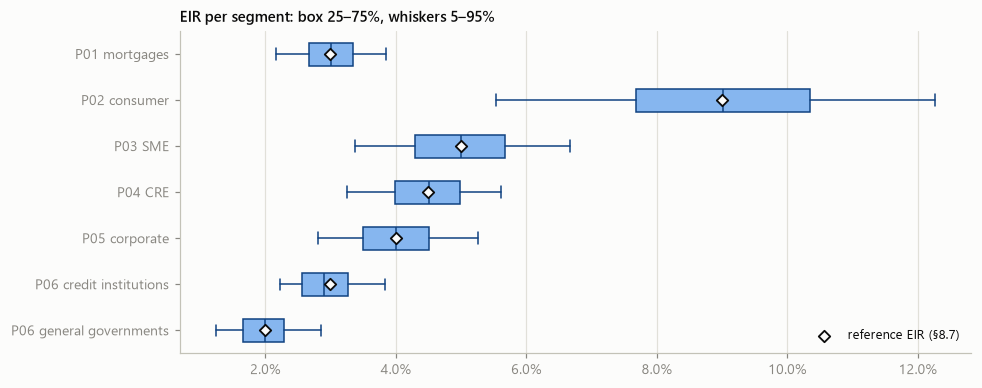

In [18]:
segments = list(rates.index)
fig, ax = plt.subplots(figsize=(9, 3.6))
edge = {"color": STAGE_COLOURS[3]}
ax.boxplot([book.loc[book["segment"] == s, "interest_rate"] for s in segments],
           orientation="horizontal", tick_labels=list(rates["label"]), whis=(5, 95),
           showfliers=False, widths=0.5, patch_artist=True,
           boxprops={"facecolor": STAGE_COLOURS[1], "edgecolor": STAGE_COLOURS[3]},
           medianprops=edge, whiskerprops=edge, capprops=edge)
ax.scatter(rates["reference EIR (§8.7)"], range(1, len(segments) + 1), marker="D", s=28,
           facecolor=SURFACE, edgecolor=INK, linewidth=1.2, zorder=3, label="reference EIR (§8.7)")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.invert_yaxis()
ax.grid(True, axis="x")
ax.grid(False, axis="y")
ax.set_title("EIR per segment: box 25–75%, whiskers 5–95%", loc="left")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

Fixed-rate and floating-rate loans per portfolio, and the GCA-weighted EIR in each stage. The generator draws the rate independently of the stage.

In [19]:
by_type = book.groupby(["portfolio", "rate_type"])
rate_types = pd.concat({
    "facilities": by_type.size().unstack(fill_value=0),
    "share of GCA": by_type["gca"].sum().div(gca, level="portfolio").unstack(fill_value=0.0),
    "mean EIR": by_type["interest_rate"].mean().unstack(),
}, axis=1)
display(rate_types.style.format(
    {c: "{:,.0f}" if c[0] == "facilities" else "{:.1%}" if c[0] == "share of GCA" else "{:.2%}"
     for c in rate_types.columns}, na_rep="–"))

by_stage = book.groupby(["portfolio", "ifrs_stage"])
stage_eir = ((book["interest_rate"] * book["gca"]).groupby([book["portfolio"], book["ifrs_stage"]])
             .sum() / by_stage["gca"].sum()).unstack()
display(stage_eir.style.format("{:.2%}").set_caption("GCA-weighted EIR per stage"))

ifrs_stage,1,2,3
portfolio,,,
P01,3.01%,3.02%,2.90%
P02,8.99%,8.99%,9.02%
P03,5.03%,5.03%,4.81%
P04,4.52%,4.48%,4.59%
P05,4.02%,3.88%,4.21%
P06,2.38%,2.57%,2.76%


## 5 · SICR triggers

The engine sets a facility's stage from its rating grades (MIG-07) and, since the owner's decision of 18 October 2026, from three qualitative triggers (MIG-05, A30):

| Stage | Trigger | Inputs |
|---|---|---|
| 3 | the current grade is D (default) | `current_grade` |
| 2 | **SICR:** the lifetime TTC PD at the current grade is at least k times the lifetime TTC PD at the origination grade | the segment's TTC matrix, `current_grade`, `origination_grade`, `residual_maturity`, and `sicr_k` in the parameter set |
| 2 | **Qualitative trigger:** 30 or more days past due, on the watchlist, or forborne, any switched-on one; it holds the facility in stage 2 until it defaults | `dpd`, `watchlist`, `forborne` with their `credit_status_date`, and `sicr_triggers` in the parameter set |
| 1 | none of the above | |

Both lifetime PDs run over the same horizon: the facility's residual maturity at the snapshot date (assumption A6). For a horizon of h = n + d years, with n whole years and a stub d < 1, the lifetime PD of grade g is

PD_life(g, h) = Mⁿ[g, D] + Σⱼ Mⁿ[g, j] · (1 − (1 − M[j, D])ᵈ),

where M is the segment's TTC matrix and the stub follows the constant-hazard convention of PD-06 (assumption A7). Each facility's SICR line is therefore fixed, and only a rating move changes its stage. A facility whose grade improves back above the line returns to stage 1, and grade D never cures. The multiple k is a synthetic test convention, not an EBA threshold (MIG-05). R3 recomputes the line for every performing facility and rejects any facility whose reported stage neither the rule nor a trigger gives back.

**Qualitative triggers.** `facilities` holds days past due (`dpd`), a `watchlist` flag and a `forborne` flag, observed on `credit_status_date`. Each switched-on trigger in the parameter set's `sicr_triggers` makes a performing facility stage 2 whatever its grade. The flags are not projected, so a flagged facility stays in stage 2 until it defaults. MIG-07's text still says they are not used; changing it is the owner's (C11). The end of this section shows how the triggers line up with the stages.

In [20]:
k_table = pd.DataFrame({
    seg: {"portfolio": v["portfolio"], "label": calibration[seg]["label"], "k": v["sicr_k"],
          "performing facilities": int(((book["segment"] == seg) & (book["ifrs_stage"] < 3)).sum())}
    for seg, v in ps["segments"].items()}).T
display(k_table)
master = pd.DataFrame({"one-year TTC PD": ps["master_scale"]["ttc_pd"]}, index=GRADES).T
display(master.style.format("{:.2%}").set_caption(
    f"Master scale: {N} performing grades plus {DEFAULT}"))

,portfolio,label,k,performing facilities
P01,P01,P01 mortgages,2.5,3920
P02,P02,P02 consumer,2.0,2880
P03,P03,P03 SME,2.5,1425
P04,P04,P04 CRE,2.5,470
P05,P05,P05 corporate,2.5,776
P06_GG,P06,P06 general governments,3.0,119
P06_CI,P06,P06 credit institutions,3.0,79


,G1,G2,G3,G4,G5,G6,G7,G8,G9,G10
one-year TTC PD,0.02%,0.05%,0.12%,0.30%,0.70%,1.60%,3.00%,4.80%,9.00%,18.00%


The TTC matrices: one per segment, with rows and columns G1…GN and D. Each row has to sum to one with no negative cell, and the D column has to equal the master-scale PD of each grade. The matrix of `SEGMENT` is shown below.

In [21]:
def matrix(segment: str) -> np.ndarray:
    """The segment's TTC matrix: rows and columns G1..GN, D."""
    part = ttc_table[ttc_table["segment"] == segment]
    table = part.pivot(index="from_grade", columns="to_grade", values="probability")
    return table.loc[LABELS, LABELS].to_numpy()


MATRICES = {seg: matrix(seg) for seg in ps["segments"]}
PD_TOL = TOL["probability_identity"]["abs"]
row_sums = np.concatenate([m.sum(axis=1) for m in MATRICES.values()])
compare("TTC matrix rows sum to one", row_sums, np.ones_like(row_sums), PD_TOL)
count_breaks("TTC matrix cells are not negative",
             np.concatenate([m.ravel() < 0 for m in MATRICES.values()]))
compare("D column of each matrix against the master-scale PD",
        np.concatenate([m[:-1, -1] for m in MATRICES.values()]),
        np.tile(ps["master_scale"]["ttc_pd"], len(MATRICES)), PD_TOL)

(pd.DataFrame(MATRICES[SEGMENT], index=pd.Index(LABELS, name="from"),
              columns=pd.Index(LABELS, name="to"))
 .style.format("{:.2%}").background_gradient(cmap="Blues", axis=None, vmin=0.0, vmax=0.25)
 .set_caption(f"TTC matrix of {SEGMENT}, one year"))

TTC matrix rows sum to one: 77 values; largest gap 2.2e-16 (limit 1e-10)
TTC matrix cells are not negative: 847 values; 0 break the rule
D column of each matrix against the master-scale PD: 70 values; largest gap 0.0e+00 (limit 1e-10)


to,G1,G2,G3,G4,G5,G6,G7,G8,G9,G10,D
from,,,,,,,,,,,
G1,90.08%,6.93%,2.08%,0.62%,0.19%,0.06%,0.02%,0.01%,0.00%,0.00%,0.02%
G2,8.10%,81.96%,6.93%,2.08%,0.62%,0.19%,0.06%,0.02%,0.01%,0.00%,0.05%
G3,1.87%,6.22%,81.90%,6.92%,2.08%,0.62%,0.19%,0.06%,0.02%,0.01%,0.12%
G4,0.52%,1.74%,5.81%,81.75%,6.91%,2.07%,0.62%,0.19%,0.06%,0.02%,0.30%
G5,0.15%,0.51%,1.70%,5.68%,81.43%,6.90%,2.07%,0.62%,0.19%,0.06%,0.70%
G6,0.05%,0.15%,0.50%,1.68%,5.59%,80.69%,6.87%,2.06%,0.62%,0.19%,1.60%
G7,0.01%,0.04%,0.15%,0.50%,1.65%,5.50%,79.54%,6.91%,2.07%,0.62%,3.00%
G8,0.00%,0.01%,0.04%,0.15%,0.49%,1.62%,5.40%,78.06%,7.25%,2.17%,4.80%
G9,0.00%,0.00%,0.01%,0.04%,0.14%,0.46%,1.55%,5.16%,74.62%,9.01%,9.00%


The SICR line rebuilt for every performing facility, with numpy only. The line is the best grade (lowest rank) at which the facility would be in stage 2. When no performing grade reaches k times the origination PD, the line is D: such a facility stays in stage 1 until it defaults. The grade rule or a qualitative trigger then has to give back every reported stage.

In [22]:
EPS = 1e-9  # float slack when a horizon is split into whole years and a stub


def lifetime_pd(segment: str, horizon: float) -> np.ndarray:
    """Lifetime TTC PD of each performing grade over `horizon` years (PD-06, A7)."""
    m = MATRICES[segment]
    whole = int(np.floor(horizon + EPS))
    stub = horizon - whole
    power = np.linalg.matrix_power(m, whole)
    life = power[:-1, -1].copy()
    if stub > EPS:
        life += power[:-1, :-1] @ (1.0 - (1.0 - m[:-1, -1]) ** stub)
    return life


def sicr_line(segment: str, horizon: float, origination: str) -> tuple[int, bool]:
    """Rank of the best grade in stage 2 (N + 1 when only D is), and whether every grade
    below it is in stage 2 too, as it is when lifetime PD rises down the scale."""
    life = lifetime_pd(segment, horizon)
    s2 = life >= ps["segments"][segment]["sicr_k"] * life[RANK[origination] - 1]
    if not s2.any():
        return N + 1, True
    first = int(np.argmax(s2)) + 1
    return first, bool(s2[first - 1:].all())


perf = book[book["ifrs_stage"] < 3].copy()
keys = list(zip(perf["segment"], perf["residual_maturity"], perf["origination_grade"]))
sicr = {key: sicr_line(key[0], float(key[1]), key[2]) for key in set(keys)}
perf["sicr_rank"] = [sicr[key][0] for key in keys]
perf["current_rank"] = perf["current_grade"].map(RANK)
perf["origination_rank"] = perf["origination_grade"].map(RANK)
TRIGGERS = ps["sicr_triggers"]
enabled = set(TRIGGERS["enabled"])
perf["trigger"] = False
if "dpd" in enabled:
    perf["trigger"] |= perf["dpd"] >= TRIGGERS["dpd_days"]
if "watchlist" in enabled:
    perf["trigger"] |= perf["watchlist"].astype(bool)
if "forborne" in enabled:
    perf["trigger"] |= perf["forborne"].astype(bool)
perf["rule_stage"] = np.where((perf["current_rank"] >= perf["sicr_rank"]) | perf["trigger"], 2, 1)

count_breaks("Stage-2 grades form one block at the bad end of the scale",
             [not sicr[key][1] for key in keys])
count_breaks("The SICR rule or a trigger gives back the stage of every performing facility (MIG-07, MIG-05)",
             perf["rule_stage"] != perf["ifrs_stage"])
observed = pd.to_datetime(book["credit_status_date"])
count_breaks("Every flag carries an observation date no later than the snapshot (section 4.2)",
             observed.isna() | (observed > pd.Timestamp(ps["horizon"]["snapshot_date"])))
count_breaks("Stage 3 exactly when the current grade is D (MIG-07)",
             (book["ifrs_stage"] == 3) != (book["current_grade"] == DEFAULT))

Stage-2 grades form one block at the bad end of the scale: 9,669 values; 0 break the rule
The SICR rule or a trigger gives back the stage of every performing facility (MIG-07, MIG-05): 9,669 values; 0 break the rule
Every flag carries an observation date no later than the snapshot (section 4.2): 10,000 values; 0 break the rule
Stage 3 exactly when the current grade is D (MIG-07): 10,000 values; 0 break the rule


How far each facility sits from its SICR line. The left block counts stage-1 facilities by the number of notches of downgrade that would move them into stage 2. "only D" means no performing grade crosses the line. That happens when the origination grade is already near the bottom of the scale, or when a loan is long enough for lifetime PDs to converge across grades, as with long mortgages. The right block counts stage-2 facilities by the number of notches of upgrade that would bring them back to stage 1. "trigger only" marks stage-2 facilities whose grade is above the line: a qualitative trigger alone holds them in stage 2, so no upgrade brings them back.

In [23]:
s1 = perf[perf["ifrs_stage"] == 1]
s2 = perf[perf["ifrs_stage"] == 2]
down = np.minimum(s1["sicr_rank"] - s1["current_rank"], 4).astype(str).str.replace("4", "4+")
down = down.where(s1["sicr_rank"] <= N, "only D")
up = np.minimum(s2["current_rank"] - s2["sicr_rank"] + 1, 3).astype(str).str.replace("3", "3+")
up = up.where(s2["current_rank"] >= s2["sicr_rank"], "trigger only")
headroom = pd.concat({
    "stage 1: notches down to stage 2": pd.crosstab(s1["segment"], down)
    .reindex(columns=["1", "2", "3", "4+", "only D"], fill_value=0),
    "stage 2: notches up to stage 1": pd.crosstab(s2["segment"], up)
    .reindex(columns=["1", "2", "3+", "trigger only"], fill_value=0),
}, axis=1).fillna(0).astype(int)
headroom.columns.names = [None, None]
headroom.insert(0, ("", "k"), [ps["segments"][s]["sicr_k"] for s in headroom.index])
headroom

stage 1: notches down to stage 2                        stage 2: notches up to stage 1                     
           k                                1     2    3   4+ only D                              1   2  3+ trigger only
segment                                                                                                                 
P01      2.5                              718  1030  711  479    582                            133  88  79          100
P02      2.0                              409  1272  533    0    216                            231  92  15          112
P03      2.5                              269   492  257   32    105                             93  92  17           68
P04      2.5                               89   154   81   28     18                             35  34   6           25
P05      2.5                              177   342  123   29      9                             47  21   4           24
P06_CI   3.0                               16    40   18    2      0                              2   0   0            1
P06_GG   3.0                               16    75   23    0      0                              2   2   0            1

The rule for `SEGMENT`, cell by cell. Each cell is the lifetime TTC PD at the current grade divided by the lifetime TTC PD at the origination grade, over the segment's median residual maturity. Cells at or above k are in stage 2. Because the horizon differs from facility to facility, a facility's own line can sit a notch away from this table. The second table shows where the segment's performing facilities actually sit, by stage.

In [24]:
horizon = float(perf.loc[perf["segment"] == SEGMENT, "residual_maturity"].median())
k = ps["segments"][SEGMENT]["sicr_k"]
life = lifetime_pd(SEGMENT, horizon)
ratio = pd.DataFrame(life[None, :] / life[:, None],
                     index=pd.Index(GRADES, name="origination grade"),
                     columns=pd.Index(GRADES, name="current grade"))


def stage_css(table: pd.DataFrame) -> pd.DataFrame:
    """Cell colours: stage 2 where the ratio reaches k, stage 1 elsewhere."""
    css = np.where(table.to_numpy() >= k,
                   f"background-color: {STAGE_COLOURS[2]}; color: white",
                   f"background-color: {STAGE_COLOURS[1]}; color: {INK}")
    return pd.DataFrame(css, index=table.index, columns=table.columns)


display(ratio.style.format("{:.2f}").apply(stage_css, axis=None).set_caption(
    f"{SEGMENT}: lifetime PD ratio over {horizon:.2f} years; stage 2 where it is at least "
    f"k = {k:g}"))

part = perf[perf["segment"] == SEGMENT]
where = pd.crosstab(part["origination_grade"], [part["ifrs_stage"], part["current_grade"]])
where = where.sort_index(key=lambda i: i.map(RANK)).sort_index(
    axis=1, key=lambda i: i.map(lambda v: RANK.get(v, v)))
where.index.name, where.columns.names = "origination grade", ["stage", "current grade"]
display(where.style.set_caption(f"{SEGMENT}: performing facilities by grade and stage"))

current grade,G1,G2,G3,G4,G5,G6,G7,G8,G9,G10
origination grade,,,,,,,,,,
G1,1.00,2.18,4.86,10.80,22.70,45.46,79.16,123.36,200.79,304.61
G2,0.46,1.00,2.23,4.95,10.40,20.82,36.26,56.50,91.97,139.53
G3,0.21,0.45,1.00,2.22,4.67,9.35,16.28,25.37,41.29,62.65
G4,0.09,0.20,0.45,1.00,2.10,4.21,7.33,11.42,18.59,28.20
G5,0.04,0.10,0.21,0.48,1.00,2.00,3.49,5.44,8.85,13.42
G6,0.02,0.05,0.11,0.24,0.50,1.00,1.74,2.71,4.42,6.70
G7,0.01,0.03,0.06,0.14,0.29,0.57,1.00,1.56,2.54,3.85
G8,0.01,0.02,0.04,0.09,0.18,0.37,0.64,1.00,1.63,2.47
G9,0.00,0.01,0.02,0.05,0.11,0.23,0.39,0.61,1.00,1.52


### Qualitative indicators in the data

IFRS 9 presumes a significant increase in credit risk once payments are more than 30 days past due (§5.5.11), and default no later than 90 days past due (§B5.5.37). The tables use the bands of the requirements, 30+ and 90+ DPD. Since 18 October 2026 the engine applies the 30-day backstop, the watchlist and the forbearance flag as stage-2 triggers (MIG-05, A30). The 90-day default backstop is not applied: stage 3 comes from grade D. The generator (O3) draws DPD, watchlist and forbearance from each facility's stage. It also makes a quarter of each segment's stage-2 facilities stage 2 by a trigger alone, with a grade above the SICR line, and no stage-1 facility carries a trigger. The obligor's `regulatory_default` is shown alongside: it is a distinct attribute that has to be reconciled with stage 3 (DAT-04).

In [25]:
dpd_band = pd.cut(book["dpd"], [-np.inf, 0, 29, 89, np.inf], labels=["0", "1–29", "30–89", "90+"])
by_s = book.groupby("ifrs_stage")
indicators = pd.concat({
    "facilities": pd.DataFrame({"all": by_s.size()}),
    "days past due": pd.crosstab(book["ifrs_stage"], dpd_band),
    "flags": pd.DataFrame({
        "watchlist": by_s["watchlist"].sum(),
        "forborne": by_s["forborne"].sum(),
        "obligor in regulatory default": by_s["regulatory_default"].sum(),
    }),
}, axis=1)
indicators.loc["Total"] = indicators.sum()
indicators.index.name = "stage"
display(indicators)

qualitative = (book["dpd"] >= 30) | book["watchlist"] | book["forborne"]
flag_only = perf.index[(perf["ifrs_stage"] == 2) & (perf["current_rank"] < perf["sicr_rank"])]
masks = {
    "stage 1 with a trigger (R3 rejects these)": qualitative & (book["ifrs_stage"] == 1),
    "stage 1 or 2 with 90+ DPD": (book["dpd"] >= 90) & (book["ifrs_stage"] < 3),
    "stage 2 with at least one trigger": qualitative & (book["ifrs_stage"] == 2),
    "stage 2 by a trigger alone, grade above the SICR line": book.index.isin(flag_only),
    "stage 2 on the grade rule alone, no trigger": ~qualitative & (book["ifrs_stage"] == 2),
}
backstops = pd.Series({label: int(mask.sum()) for label, mask in masks.items()},
                      name="facilities")
display(backstops.to_frame())
n_s2 = int((book["ifrs_stage"] == 2).sum())
display(Markdown(
    f"**{backstops.iloc[2]:,}** of the {n_s2:,} stage-2 facilities carry a trigger, "
    f"**{backstops.iloc[3]:,}** of them as their only reason for stage 2; "
    f"**{backstops.iloc[4]:,}** are in stage 2 through the grade rule with no trigger. "
    f"No stage-1 facility carries a trigger ({backstops.iloc[0]:,})."))

facilities days past due                      flags                                       
             all             0  1–29 30–89  90+ watchlist forborne obligor in regulatory default
stage                                                                                           
1           8345          7925   420     0    0         0        0                             0
2           1324            23   820   481    0       562      168                             0
3            331             0     0     0  331       331       97                           331
Total      10000          7948  1240   481  331       893      265                           331

,facilities
stage 1 with a trigger (R3 rejects these),0
stage 1 or 2 with 90+ DPD,0
stage 2 with at least one trigger,960
"stage 2 by a trigger alone, grade above the SICR line",331
"stage 2 on the grade rule alone, no trigger",364


**960** of the 1,324 stage-2 facilities carry a trigger, **331** of them as their only reason for stage 2; **364** are in stage 2 through the grade rule with no trigger. No stage-1 facility carries a trigger (0).

## 6 · Other inputs at a glance

### Opening provisions

The opening allowances were calculated once by O4 with a TTC formula (SYN-PAR-09) and frozen at the snapshot date. A run never recalculates them. Coverage is the on-balance allowance divided by GCA. The off-balance provision covers the undrawn commitments.

In [26]:
allowance = book.pivot_table(index="portfolio", columns="ifrs_stage", values="allowance_on",
                             aggfunc="sum")
coverage = allowance / book.pivot_table(index="portfolio", columns="ifrs_stage", values="gca",
                                        aggfunc="sum")
off = by_p[["nominal_undrawn", "provision_off"]].sum()
opening = pd.concat({
    "allowance €m": allowance / 1e6,
    "coverage of GCA": coverage,
    "off-balance": pd.DataFrame({"undrawn €m": off["nominal_undrawn"] / 1e6,
                                 "provision €m": off["provision_off"] / 1e6}),
}, axis=1)
print(f"method: {listed(provisions['method'])}; all frozen: {bool(provisions['frozen'].all())}; "
      f"overlays: {int((provisions['overlay_amount'] != 0).sum())}")

totals = manifest["control_totals"]
expected = [totals["gca_total"], totals["undrawn_total"], totals["allowance_on_total"],
            totals["provision_off_total"]]
compare("GCA, undrawn, allowance and off-balance provision against the manifest totals, EUR",
        [book["gca"].sum(), book["nominal_undrawn"].sum(), provisions["allowance_on"].sum(),
         provisions["provision_off"].sum()], expected, aggregate_limit(expected))
opening.style.format({c: "{:.2%}" if c[0] == "coverage of GCA" else "{:,.2f}"
                      for c in opening.columns}, na_rep="–")

method: O4 TTC formula v1 (SYN-PAR-09); all frozen: True; overlays: 0
GCA, undrawn, allowance and off-balance provision against the manifest totals, EUR: 4 values; largest gap 2.4e-07 (limit 1e+02)


### Calibration of the TTC matrices

SYN-PAR-05 calibrates each segment's matrix so that the one-year TTC PD of the grades holding its stage-1 exposures, weighted by drawn exposure, equals the stage-1 target in §8.7. The same holds for stage 2. Drawn exposure is GCA where accrued interest is in GCA, and principal plus accrued interest otherwise.

In [27]:
drawn = book["gca"].where(book["accrued_in_gca"], book["principal"] + book["accrued_interest"])
mask = book["ifrs_stage"] < 3
keys = [book.loc[mask, "segment"], book.loc[mask, "ifrs_stage"]]
average = ((book.loc[mask, "ttc_pd"] * drawn[mask]).groupby(keys).sum()
           / drawn[mask].groupby(keys).sum()).unstack()
calibrated = pd.DataFrame({
    "label": {s: v["label"] for s, v in calibration.items()},
    "stage 1 target": {s: v["s1_pd"] for s, v in calibration.items()},
    "stage 1 in data": average[1],
    "stage 2 target": {s: v["s2_pd"] for s, v in calibration.items()},
    "stage 2 in data": average[2],
})
compare("Weighted one-year TTC PD per segment and stage against §8.7 (SYN-PAR-05)",
        calibrated[["stage 1 in data", "stage 2 in data"]].to_numpy().ravel(),
        calibrated[["stage 1 target", "stage 2 target"]].to_numpy().ravel(), PD_TOL)
calibrated.style.format("{:.3%}", subset=list(calibrated.columns[1:]))

Weighted one-year TTC PD per segment and stage against §8.7 (SYN-PAR-05): 14 values; largest gap 6.2e-17 (limit 1e-10)


,label,stage 1 target,stage 1 in data,stage 2 target,stage 2 in data
P01,P01 mortgages,0.800%,0.800%,4.000%,4.000%
P02,P02 consumer,3.000%,3.000%,12.000%,12.000%
P03,P03 SME,2.000%,2.000%,8.000%,8.000%
P04,P04 CRE,1.500%,1.500%,6.000%,6.000%
P05,P05 corporate,1.000%,1.000%,5.000%,5.000%
P06_CI,P06 credit institutions,0.200%,0.200%,1.500%,1.500%
P06_GG,P06 general governments,0.050%,0.050%,0.500%,0.500%


### Parameter set

The values for each segment, as the parameter set proposes them. They are synthetic test conventions, not estimated or EBA-prescribed parameters (SYN-PAR-06). The Z-score drivers move the TTC matrix (through ρ), the LGD (through w) and the prepayment rate (through v).

In [28]:
params = pd.DataFrame({
    seg: {
        "portfolio": v["portfolio"],
        "Z drivers (β)": ", ".join(f"{name} ({d['beta']:+g})" for name, d in v["z_drivers"].items()),
        "ρ": v["rho"], "SICR k": v["sicr_k"], "LGD w": v["lgd_w"], "CPR TTC": v["cpr_ttc"],
        "CPR v": v["cpr_v"], "CCF": v["ccf"],
    } for seg, v in ps["segments"].items()}).T
horizon_info = ps["horizon"]
print(f"{ps['parameter_set_id']} v{ps['version']} ({ps['status']}); projection years "
      f"{', '.join(str(y) for y in horizon_info['projection_years'])}; buckets to "
      f"{horizon_info['last_bucket_year']}; terminal rule {ps['terminal_rule']['method']} over "
      f"{ps['terminal_rule']['reversion_years']} years; variants {', '.join(ps['variants'])}")
params.style.format("{:g}", subset=["ρ", "SICR k", "LGD w", "CPR TTC", "CPR v", "CCF"],
                    na_rep="–")

SYN-PS-0.1-proposed v0.1 (PROPOSED); projection years 2027, 2028, 2029; buckets to 2060; terminal rule linear_reversion_to_baseline over 6 years; variants core, annuity, linear, utilisation


,portfolio,Z drivers (β),ρ,SICR k,LGD w,CPR TTC,CPR v,CCF
P01,P01,"gdp_growth (+0.4), unemployment (-0.3), residential_price_change (+0.3)",0.15,2.5,0.2,0.06,0.25,–
P02,P02,"gdp_growth (+0.5), unemployment (-0.5)",0.06,2,0.1,0.1,0.2,–
P03,P03,"gdp_growth (+0.6), unemployment (-0.2), reference_rate (-0.2)",0.12,2.5,0.15,0.05,0.15,0.5
P04,P04,"gdp_growth (+0.3), cre_price_change (+0.5), reference_rate (-0.2)",0.15,2.5,0.25,0.03,0.15,–
P05,P05,"gdp_growth (+0.7), reference_rate (-0.3)",0.12,2.5,0.15,0.05,0.15,0.5
P06_GG,P06,"gdp_growth (+0.8), reference_rate (-0.2)",0.2,3,0.1,0,0,–
P06_CI,P06,"gdp_growth (+0.6), unemployment (-0.2), reference_rate (-0.2)",0.2,3,0.1,0,0,–


### Scenarios

Every variable has one path per scenario, country and projection year. The values are in the units the file states (percent). Where all countries share the same path, their lines in the chart overlap.

SYN-SCN-1.3 (SYNTHETIC), source: requirements v1.3 section 6.2 (illustrative common paths); 180 values for 6 countries; at most 1 distinct value(s) per scenario, variable and year


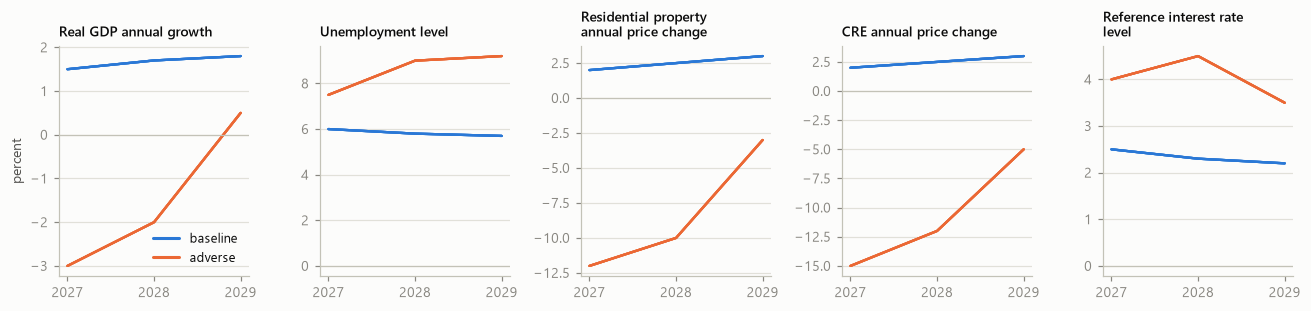

scenario                         adverse            baseline          
year                                2027  2028 2029     2027 2028 2029
variable                 country                                      
cre_price_change         DE        -15.0 -12.0 -5.0      2.0  2.5  3.0
                         ES        -15.0 -12.0 -5.0      2.0  2.5  3.0
                         FR        -15.0 -12.0 -5.0      2.0  2.5  3.0
                         IT        -15.0 -12.0 -5.0      2.0  2.5  3.0
                         NL        -15.0 -12.0 -5.0      2.0  2.5  3.0
                         PL        -15.0 -12.0 -5.0      2.0  2.5  3.0
gdp_growth               DE         -3.0  -2.0  0.5      1.5  1.7  1.8
                         ES         -3.0  -2.0  0.5      1.5  1.7  1.8
                         FR         -3.0  -2.0  0.5      1.5  1.7  1.8
                         IT         -3.0  -2.0  0.5      1.5  1.7  1.8
                         NL         -3.0  -2.0  0.5      1.5  1.7  1.8
                         PL         -3.0  -2.0  0.5      1.5  1.7  1.8
reference_rate           DE          4.0   4.5  3.5      2.5  2.3  2.2
                         ES          4.0   4.5  3.5      2.5  2.3  2.2
                         FR          4.0   4.5  3.5      2.5  2.3  2.2
                         IT          4.0   4.5  3.5      2.5  2.3  2.2
                         NL          4.0   4.5  3.5      2.5  2.3  2.2
                         PL          4.0   4.5  3.5      2.5  2.3  2.2
residential_price_change DE        -12.0 -10.0 -3.0      2.0  2.5  3.0
                         ES        -12.0 -10.0 -3.0      2.0  2.5  3.0
                         FR        -12.0 -10.0 -3.0      2.0  2.5  3.0
                         IT        -12.0 -10.0 -3.0      2.0  2.5  3.0
                         NL        -12.0 -10.0 -3.0      2.0  2.5  3.0
                         PL        -12.0 -10.0 -3.0      2.0  2.5  3.0
unemployment             DE          7.5   9.0  9.2      6.0  5.8  5.7
                         ES          7.5   9.0  9.2      6.0  5.8  5.7
                         FR          7.5   9.0  9.2      6.0  5.8  5.7
                         IT          7.5   9.0  9.2      6.0  5.8  5.7
                         NL          7.5   9.0  9.2      6.0  5.8  5.7
                         PL          7.5   9.0  9.2      6.0  5.8  5.7

In [29]:
values = pd.DataFrame(scenario_doc["values"])
variables = pd.DataFrame(scenario_doc["variables"]).set_index("id")
spread = values.groupby(["scenario", "variable", "year"])["value"].nunique().max()
print(f"{scenario_doc['scenario_set_id']} ({scenario_doc['status']}), source: "
      f"{scenario_doc['source']}; {len(values)} values for {values['country'].nunique()} "
      f"countries; at most {spread} distinct value(s) per scenario, variable and year")

years = sorted(values["year"].unique())
fig, axes = plt.subplots(1, len(variables), figsize=(12, 2.9))
for ax, (variable, meta) in zip(axes, variables.iterrows()):
    for (scenario, _), line in values[values["variable"] == variable].groupby(
            ["scenario", "country"]):
        line = line.sort_values("year")
        ax.plot(line["year"], line["value"], color=SCENARIO_COLOURS[scenario], alpha=0.7,
                linewidth=1.5)
    ax.set_title("\n".join(textwrap.wrap(meta["label"], 24)), loc="left", fontsize=9)
    ax.set_xticks(years)
    ax.axhline(0, color=AXIS, linewidth=0.8)
axes[0].set_ylabel("percent")
handles = [plt.Line2D([], [], color=c, label=s) for s, c in SCENARIO_COLOURS.items()]
axes[0].legend(handles=handles, loc="lower right")
fig.tight_layout()
plt.show()

values.pivot_table(index=["variable", "country"], columns=["scenario", "year"], values="value")

## 7 · Summary of the checks

Every check above, against its limit. The limits come from the tolerances in `targets.yaml`: exact for counts, 1e-10 for shares and probabilities, and for amounts the larger of €1 and 1e-8 of the amount. For a rule, the gap is the number of values that break it. The last line stops "Run all" if any check fails.

In [30]:
summary = pd.DataFrame(CHECKS)
summary["passed"] = summary["gap"] <= summary["limit"]  # a missing value (NaN) fails
display(summary.style.format({"values": "{:,}", "gap": "{:.1e}", "limit": "{:.0e}"}))
assert summary["passed"].all(), "the input set differs from its manifest or from a target"

,check,values,gap,limit,passed
0,Folder name is the start of the content hash,1,0.0e+00,0e+00,True
1,Each file's SHA-256 against the manifest,7,0.0e+00,0e+00,True
2,Rows of each table against the manifest,5,0.0e+00,0e+00,True
3,Every facility in EUR at AC,"10,000",0.0e+00,0e+00,True
4,Facilities per portfolio against §5.1,6,0.0e+00,0e+00,True
5,"GCA per portfolio against §5.1, EUR",6,1.4e-06,4e+01,True
6,"Undrawn per portfolio against §5.1, EUR",6,0.0e+00,1e+01,True
7,IRB share of GCA per portfolio against §5.3,6,6.1e-16,1e-10,True
8,"GCA per regulatory approach against §5.3, EUR",2,9.5e-07,6e+01,True
9,P06 share of GCA per counterparty sector against §5.3,2,3.9e-16,1e-10,True


### In short

The answers to the four questions, written from the data above.

In [31]:
weighted_rate = (book["interest_rate"] * book["gca"]).groupby(book["portfolio"]).sum() / gca
k_by_segment = ", ".join(f"{s} {v['sicr_k']:g}" for s, v in ps["segments"].items())
portfolio_text = (
    f"**Portfolios.** {len(NAMES)} portfolios in {len(ps['segments'])} reference segments: "
    + "; ".join(f"{p} {NAMES[p]}, EUR {gca[p] / 1e6:,.0f} million" for p in NAMES) + ".")
loan_text = (
    f"**Loans.** {len(book):,} facilities to {book['obligor_id'].nunique():,} obligors: "
    f"EUR {gca.sum() / 1e6:,.0f} million GCA, plus EUR {book['nominal_undrawn'].sum() / 1e6:,.0f} "
    f"million undrawn on {len(commitments):,} commitments. "
    + ", ".join(f"{(book['ifrs_stage'] == s).sum():,} are in stage {s}" for s in STAGES) + ".")
rate_text = (
    f"**Interest rates.** EIRs run from {book['interest_rate'].min():.2%} to "
    f"{book['interest_rate'].max():.2%}. The GCA-weighted mean per portfolio is "
    + ", ".join(f"{p} {weighted_rate[p]:.2%}" for p in NAMES)
    + f". {(book['rate_type'] == 'floating').mean():.0%} of the facilities are floating-rate, "
    "but every rate keeps its snapshot value through the projection.")
sicr_text = (
    "**SICR triggers.** Stage 2 when the lifetime TTC PD at the current grade is at least k times "
    "the lifetime TTC PD at the origination grade, over the residual maturity, with "
    f"k = {k_by_segment}, or when the facility is {ps['sicr_triggers']['dpd_days']}+ days past due, "
    "on the watchlist or forborne; a trigger holds it in stage 2 until default. Stage 3 means "
    f"grade D. {backstops.iloc[2]:,} of the {n_s2:,} stage-2 facilities carry a trigger, "
    f"{backstops.iloc[3]:,} as their only reason.")
display(Markdown(f"{portfolio_text}\n\n{loan_text}\n\n{rate_text}\n\n{sicr_text}"))

**Portfolios.** 6 portfolios in 7 reference segments: P01 Residential mortgages, EUR 1,200 million; P02 Consumer credit, EUR 60 million; P03 SME lending, EUR 1,500 million; P04 Commercial real estate, EUR 2,000 million; P05 Corporate lending, EUR 4,000 million; P06 Sovereigns and credit institutions, EUR 2,240 million.

**Loans.** 10,000 facilities to 8,320 obligors: EUR 11,000 million GCA, plus EUR 2,000 million undrawn on 931 commitments. 8,345 are in stage 1, 1,324 are in stage 2, 331 are in stage 3.

**Interest rates.** EIRs run from 0.80% to 17.30%. The GCA-weighted mean per portfolio is P01 3.01%, P02 8.99%, P03 5.02%, P04 4.51%, P05 4.01%, P06 2.39%. 28% of the facilities are floating-rate, but every rate keeps its snapshot value through the projection.

**SICR triggers.** Stage 2 when the lifetime TTC PD at the current grade is at least k times the lifetime TTC PD at the origination grade, over the residual maturity, with k = P01 2.5, P02 2, P03 2.5, P04 2.5, P05 2.5, P06_GG 3, P06_CI 3, or when the facility is 30+ days past due, on the watchlist or forborne; a trigger holds it in stage 2 until default. Stage 3 means grade D. 960 of the 1,324 stage-2 facilities carry a trigger, 331 as their only reason.